<a href="https://colab.research.google.com/github/theatu824/MSSP607-GitHub/blob/main/Assignments/Assignmen1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
from google.colab import userdata
import os
github_token = userdata.get('github_token')
owner = 'theatu824' # Replace with the GitHub repository owner
repository = 'MSSP607-GitHub' # Replace with the GitHub repository name
clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'
# Clone the repository
import subprocess
subprocess.run(['git', 'clone', clone_url])
# Navigate into the cloned repository directory (optional, but often useful)
os.chdir(repository)
print(f"Changed directory to: {os.getcwd()}")

Changed directory to: /content/MSSP607-GitHub


In [2]:
df = pd.read_excel("data/data_academic_performance 2.xlsx")
df.head()

,COD_S11,GENDER,EDU_FATHER,EDU_MOTHER,OCC_FATHER,OCC_MOTHER,STRATUM,SISBEN,PEOPLE_HOUSE,Unnamed: 9,...,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
0,SB11201210000129,F,Incomplete Professional Education,Complete technique or technology,Technical or professional level employee,Home,Stratum 4,It is not classified by the SISBEN,Three,NaN,...,71,93,79,181,180,91,5,4,2,2
1,SB11201210000137,F,Complete Secundary,Complete professional education,Entrepreneur,Independent professional,Stratum 5,It is not classified by the SISBEN,Three,NaN,...,86,98,78,201,182,92,5,4,4,4
2,SB11201210005154,M,Not sure,Not sure,Independent,Home,Stratum 2,Level 2,Five,NaN,...,18,43,22,113,113,7,1,1,1,1
3,SB11201210007504,F,Not sure,Not sure,Other occupation,Independent,Stratum 2,It is not classified by the SISBEN,Three,NaN,...,76,80,48,137,157,67,4,3,2,2
4,SB11201210007548,M,Complete professional education,Complete professional education,Executive,Home,Stratum 4,It is not classified by the SISBEN,One,NaN,...,98,100,71,189,198,98,5,4,4,2


In [ ]:
#Initial Data Inspection
print("Rows and columns:", df.shape)
df.info()

Rows and columns: (12411, 45)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12411 entries, 0 to 12410
Data columns (total 45 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   COD_S11           12411 non-null  object 
 1   GENDER            12411 non-null  object 
 2   EDU_FATHER        12411 non-null  object 
 3   EDU_MOTHER        12411 non-null  object 
 4   OCC_FATHER        12411 non-null  object 
 5   OCC_MOTHER        12411 non-null  object 
 6   STRATUM           12411 non-null  object 
 7   SISBEN            12411 non-null  object 
 8   PEOPLE_HOUSE      12411 non-null  object 
 9   Unnamed: 9        0 non-null      float64
 10  INTERNET          12411 non-null  object 
 11  TV                12411 non-null  object 
 12  COMPUTER          12411 non-null  object 
 13  WASHING_MCH       12411 non-null  object 
 14  MIC_OVEN          12411 non-null  object 
 15  CAR               12411 non-null  object 
 16  DVD       

In [3]:
# Remove the entirely empty column and retain the original dataset
df_clean = df.drop(columns=["Unnamed: 9"])

Variable Selection and Initial Inspection

  -Outcome Variable construction

In [ ]:
#Six-Domain Composite Score Construction
composite_columns = [
    "QR_PRO",
    "CR_PRO",
    "CC_PRO",
    "WC_PRO",
    "ENG_PRO",
    "FEP_PRO"
]

scores = df_clean[composite_columns]
scores.describe().round(2)

,QR_PRO,CR_PRO,CC_PRO,WC_PRO,ENG_PRO,FEP_PRO
count,12411.00,12411.00,12411.00,12411.00,12411.00,12411.00
mean,77.42,62.20,59.19,53.70,67.50,145.48
std,22.67,27.67,28.99,30.00,25.50,40.13
min,1.00,1.00,1.00,0.00,1.00,1.00
25%,65.00,42.00,36.00,28.00,51.00,124.00
50%,85.00,67.00,65.00,56.00,74.00,153.00
75%,96.00,86.00,85.00,80.00,88.00,174.00
max,100.00,100.00,100.00,100.00,100.00,300.00


In [ ]:
#Identify students with all six scores
complete_scores = scores.notna().all(axis=1)
reference_scores = scores.loc[complete_scores]

print("Total students:", len(df_clean))
print("Students with all six scores:", int(complete_scores.sum()))
print("Students without all six scores:", int((~complete_scores).sum()))

if len(reference_scores) < 2:
    raise ValueError("Too few complete records to construct the composite.")

Total students: 12411
Students with all six scores: 12411
Students without all six scores: 0


In [ ]:
#Calculate reference means and sample standard deviations
score_means = reference_scores.mean().round(2)
score_sds = reference_scores.std(ddof=1).round(2)

if (score_sds.isna() | score_sds.eq(0)).any():
    raise ValueError(
        "At least one domain has an undefined or zero standard deviation."
    )

# Retain the standardization parameters for documentation
standardization_parameters = pd.DataFrame({
    "Reference mean": score_means,
    "Reference standard deviation": score_sds
})

display(standardization_parameters)

,Reference mean,Reference standard deviation
QR_PRO,77.42,22.67
CR_PRO,62.20,27.67
CC_PRO,59.19,28.99
WC_PRO,53.70,30.00
ENG_PRO,67.50,25.50
FEP_PRO,145.48,40.13


In [ ]:
#Standardize each domain using the same reference sample
z_columns = [f"{column}_Z" for column in composite_columns]

z_scores = scores.sub(score_means).div(score_sds)
z_scores.columns = z_columns

df_clean[z_columns] = z_scores

#Compute an equally weighted six-domain composite
df_clean["COMPOSITE_6_Z"] = z_scores.mean(axis=1, skipna=False)

display(df_clean["COMPOSITE_6_Z"].describe().round(2))

display(
    df_clean[
        composite_columns + ["COMPOSITE_6_Z"]
    ].head().round(2)
)

,COMPOSITE_6_Z
count,12411.00
mean,-0.00
std,0.68
min,-2.23
25%,-0.48
50%,0.06
75%,0.54
max,1.57


,QR_PRO,CR_PRO,CC_PRO,WC_PRO,ENG_PRO,FEP_PRO,COMPOSITE_6_Z
0,71,93,71,79,93,181,0.66
1,97,38,86,78,98,201,0.72
2,17,1,18,22,43,113,-1.52
3,65,35,76,48,80,137,-0.14
4,94,94,98,71,100,189,1.03


-compare the outcomes

In [ ]:
# Inspect category labels and group sizes
categorical_columns = [
    "GENDER",
    "EDU_FATHER",
    "EDU_MOTHER",
    "STRATUM",
    "INTERNET"
]

for column in categorical_columns:
    print(f"\n{column}")
    print(df_clean[column].value_counts(dropna=False))


GENDER
GENDER
M    7368
F    5043
Name: count, dtype: int64

EDU_FATHER
EDU_FATHER
Complete professional education          3016
Complete Secundary                       2843
Complete technique or technology         1194
Incomplete Secundary                     1091
Postgraduate education                   1085
Complete primary                          824
Incomplete primary                        735
Incomplete Professional Education         425
Not sure                                  407
0                                         391
Incomplete technical or technological     277
Ninguno                                   123
Name: count, dtype: int64

EDU_MOTHER
EDU_MOTHER
Complete Secundary                       3106
Complete professional education          3059
Complete technique or technology         1495
Incomplete Secundary                     1056
Postgraduate education                    997
Complete primary                          713
Incomplete primary                     

1. parental education

In [ ]:
all_parent_education = pd.concat([
    df_clean["EDU_FATHER"],
    df_clean["EDU_MOTHER"]
])

print(all_parent_education.unique())

['Incomplete Professional Education' 'Complete Secundary' 'Not sure'
 'Complete professional education' 'Incomplete Secundary'
 'Incomplete technical or technological'
 'Complete technique or technology' 'Incomplete primary '
 'Complete primary ' 'Postgraduate education' 0 'Ninguno']


In [ ]:
# Map the original education categories to four broad levels
education_mapping = {
    "Ninguno": 1,
    "Incomplete primary ": 1,
    "Complete primary ": 1,
    "Incomplete Secundary": 1,
    "Complete Secundary": 2,
    "Incomplete technical or technological": 3,
    "Incomplete Professional Education": 3,
    "Complete technique or technology": 4,
    "Complete professional education": 4,
    "Postgraduate education": 4
}

df_clean["FATHER_EDU_LEVEL"] = (
    df_clean["EDU_FATHER"].map(education_mapping).astype("Int64")
)

df_clean["MOTHER_EDU_LEVEL"] = (
    df_clean["EDU_MOTHER"].map(education_mapping).astype("Int64")
)

for original, grouped in [
    ("EDU_FATHER", "FATHER_EDU_LEVEL"),
    ("EDU_MOTHER", "MOTHER_EDU_LEVEL")
]:
    print(f"\nUnclassified categories in {original}:")
    print(
        df_clean.loc[df_clean[grouped].isna(), original]
        .value_counts(dropna=False)
    )

# Construct unordered parental education combinations
def make_parent_group(row):
    father = row["FATHER_EDU_LEVEL"]
    mother = row["MOTHER_EDU_LEVEL"]

    if pd.isna(father) or pd.isna(mother):
        return "Unclassified"

    lower, higher = sorted([int(father), int(mother)])
    return f"{lower} + {higher}"

df_clean["PARENT_EDU_GROUP"] = df_clean[
    ["FATHER_EDU_LEVEL", "MOTHER_EDU_LEVEL"]
].apply(make_parent_group, axis=1)

# Inspect the sizes of the newly constructed groups
display(
    df_clean["PARENT_EDU_GROUP"]
    .value_counts()
    .sort_index()
    .rename("n")
    .to_frame()
)


Unclassified categories in EDU_FATHER:
EDU_FATHER
Not sure    407
0           391
Name: count, dtype: int64

Unclassified categories in EDU_MOTHER:
EDU_MOTHER
0           388
Not sure    179
Name: count, dtype: int64


,n
PARENT_EDU_GROUP,
1 + 1,1527
1 + 2,1155
1 + 3,145
1 + 4,584
2 + 2,1449
2 + 3,288
2 + 4,1510
3 + 3,187
3 + 4,716


In [ ]:
parent_summary = (
    df_clean.groupby("PARENT_EDU_GROUP")["COMPOSITE_6_Z"]
      .agg(["count", "mean", "median", "std"])
)

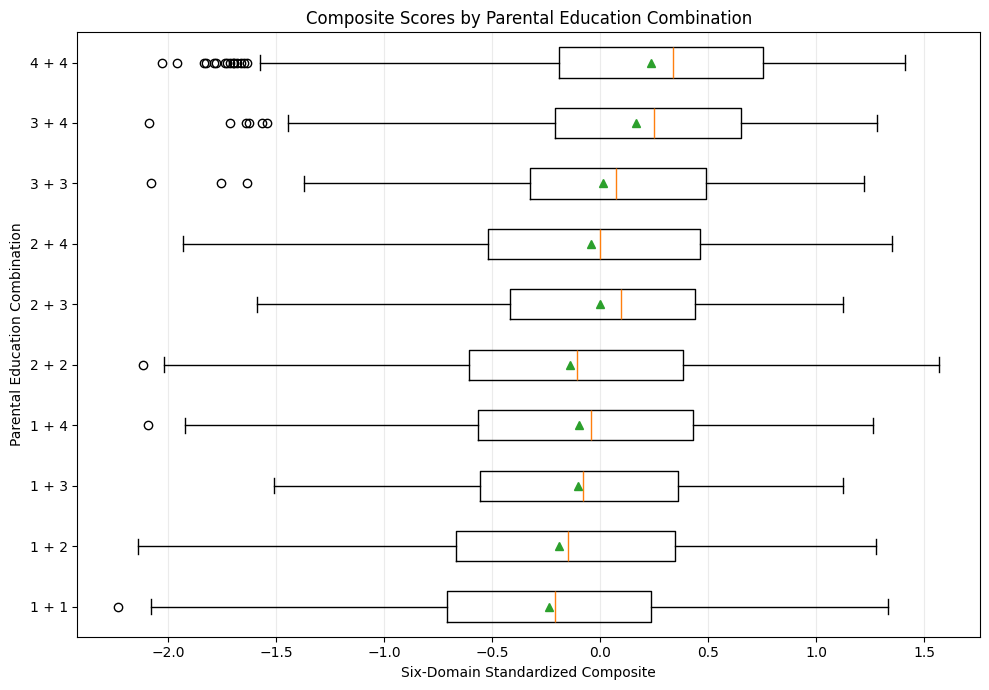

In [ ]:
#horizontal boxplot
group_labels = parent_summary.drop(index="Unclassified").index

group_scores = []

for group in group_labels:
    scores_in_group = df_clean.loc[
        df_clean["PARENT_EDU_GROUP"] == group,
        "COMPOSITE_6_Z"
    ]
    group_scores.append(scores_in_group)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.boxplot(
    group_scores,
    tick_labels=group_labels,
    orientation="horizontal",
    showmeans=True
)

plt.xlabel("Six-Domain Standardized Composite")
plt.ylabel("Parental Education Combination")
plt.title("Composite Scores by Parental Education Combination")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

2. Stratums and groups

In [ ]:
df_clean["STRATUM"].value_counts(dropna=False)

,count
STRATUM,
Stratum 3,4045
Stratum 2,4029
Stratum 1,1709
Stratum 4,1578
Stratum 5,633
Stratum 6,403
0,14


In [ ]:
stratum_summary = (
    df_clean.groupby("STRATUM")["COMPOSITE_6_Z"]
      .agg(["count", "mean", "median", "std"])
)
stratum_summary
stratum_summary.round(2).to_excel("stratum_summary.xlsx")

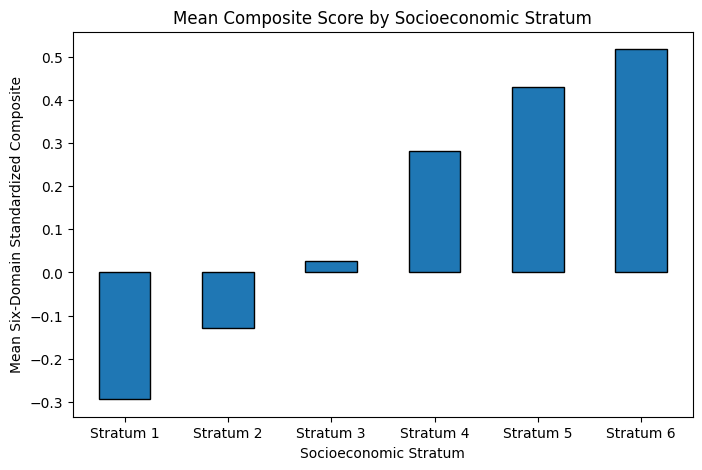

In [ ]:
stratum_summary.loc[
    ["Stratum 1", "Stratum 2", "Stratum 3",
     "Stratum 4", "Stratum 5", "Stratum 6"],
    "mean"
].plot(kind="bar",
       figsize=(8, 5),
       rot = 0,
       edgecolor="black")
plt.title("Mean Composite Score by Socioeconomic Stratum")
plt.xlabel("Socioeconomic Stratum")
plt.ylabel("Mean Six-Domain Standardized Composite")
plt.show()


3. gender and global assessment

In [ ]:
gender_summary = (
    df_clean.groupby("GENDER")["G_SC"]
      .agg(["count", "mean", "median", "std"])
)
gender_summary
gender_summary.round(2).to_excel("gender_summary.xlsx")

,count,mean,median,std
GENDER,,,,
F,5043,161.28,162.00,22.33
M,7368,163.69,164.00,23.58


In [ ]:
# Calculate the mean difference using unrounded student-level data
gender_means = df_clean.groupby("GENDER")["G_SC"].mean()

female_mean = gender_means.loc["F"]
male_mean = gender_means.loc["M"]
mean_difference = male_mean - female_mean

display(gender_summary.round(2))

print(f"Female mean global score: {female_mean:.2f}")
print(f"Male mean global score: {male_mean:.2f}")
print(f"Mean difference (Male minus Female): {mean_difference:.2f}")

,count,mean,median,std
GENDER,,,,
F,5043,161.28,162.00,22.33
M,7368,163.69,164.00,23.58


Female mean global score: 161.28
Male mean global score: 163.69
Mean difference (Male minus Female): 2.41


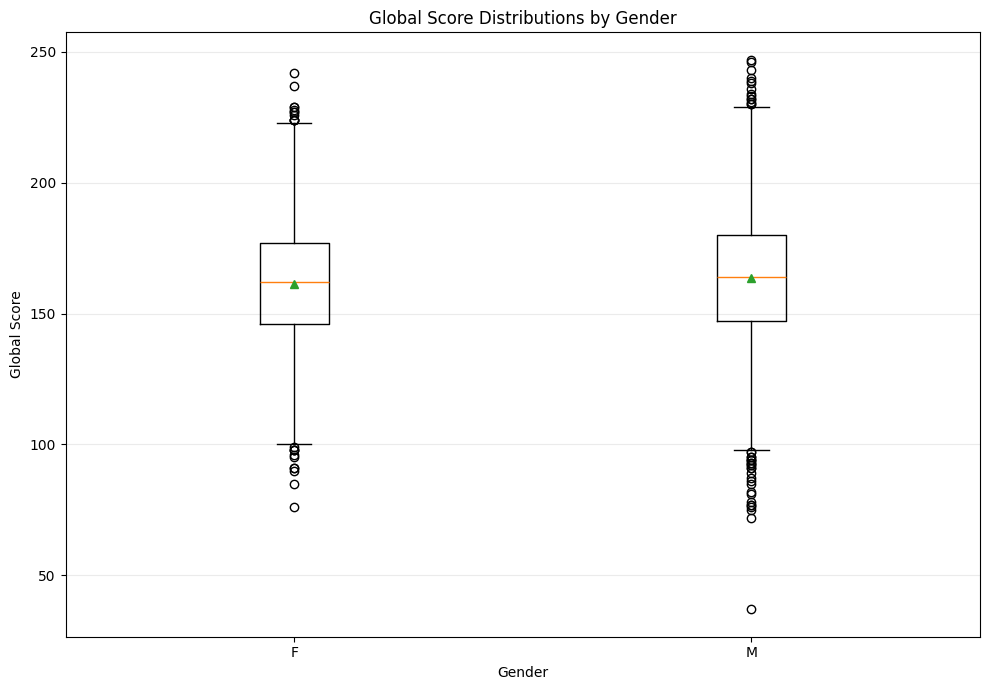

In [ ]:
gender_labels = df_clean["GENDER"].unique()

gender_scores = []

for g in gender_labels:
    gsc_in_group = df_clean.loc[
        df_clean["GENDER"] == g,
        "G_SC"
    ]
    gender_scores.append(gsc_in_group)

plt.figure(figsize=(10, 7))

plt.boxplot(
    gender_scores,
    tick_labels=gender_labels,
    showmeans=True
)

plt.xlabel("Gender")
plt.ylabel("Global Score")
plt.title("Global Score Distributions by Gender")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

4. Explore the relationship between the change in citizenship and the whether family possess Internet.

In [ ]:
df_clean["INTERNET"].value_counts().sort_index()

,count
INTERNET,
No,2659
Yes,9752


In [7]:
# Inspect citizenship competency scores at both assessment stages
score_columns = ["CC_S11", "CC_PRO"]

display(df_clean[score_columns].describe().round(2))

,CC_S11,CC_PRO
count,12411.00,12411.00
mean,60.71,59.19
std,10.12,28.99
min,0.00,1.00
25%,54.00,36.00
50%,60.00,65.00
75%,67.00,85.00
max,100.00,100.00


In [8]:
#standardize Citizenship Competency Scores
s11_mean = df_clean["CC_S11"].mean( )
s11_sd = df_clean["CC_S11"].std(ddof=1)
df_clean["z_s11"] = df_clean["CC_S11"].sub(s11_mean).div(s11_sd)

pro_mean = df_clean["CC_PRO"].mean( )
pro_sd = df_clean["CC_PRO"].std(ddof=1)
df_clean["z_pro"] = df_clean["CC_PRO"].sub(pro_mean).div(pro_sd)

,cc_dif
INTERNET,
No,0.01
Yes,-0.00


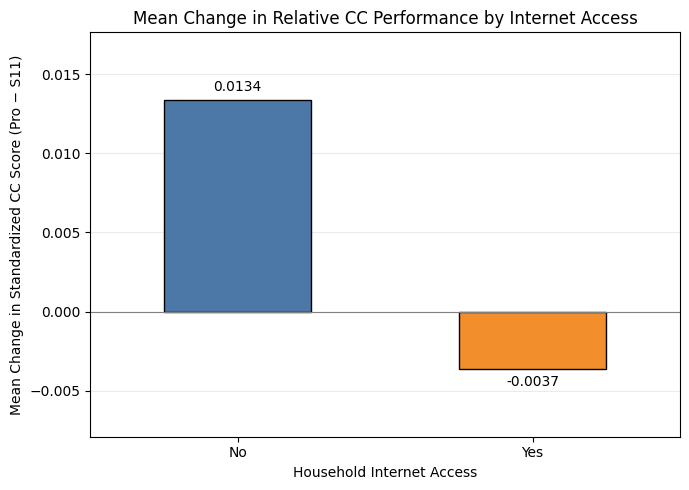

In [9]:
# Calculate each student's change in standardized score
df_clean["cc_dif"] = df_clean["z_pro"] - df_clean["z_s11"]

# Calculate mean individual change within each internet-access group
internet_change_means = (
    df_clean.groupby("INTERNET")["cc_dif"]
    .mean()
    .reindex(["No", "Yes"])
)

display(internet_change_means.round(4))

ax = internet_change_means.plot(
    kind="bar",
    figsize=(7, 5),
    rot=0,
    color=["#4C78A8", "#F28E2B"],
    edgecolor="black"
)

# Label the bars with their mean changes
ax.bar_label(ax.containers[0], fmt="%.4f", padding=4)

plt.xlabel("Household Internet Access")
plt.ylabel("Mean Change in Standardized CC Score (Pro − S11)")
plt.title("Mean Change in Relative CC Performance by Internet Access")
plt.axhline(y=0, color="gray", linewidth=0.8)
plt.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.margins(y=0.25)
plt.tight_layout()
plt.show()

,z_s11,z_pro
INTERNET,,
No,-0.22,-0.21
Yes,0.06,0.06


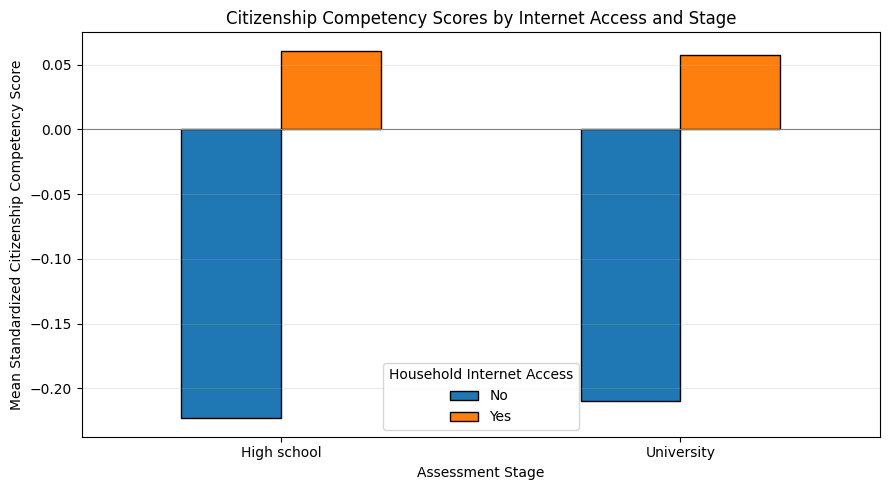

In [19]:
# Calculate mean standardized scores by internet access
internet_stage_means = (
    df_clean.groupby("INTERNET")[["z_s11", "z_pro"]]
    .mean()
)
display(internet_stage_means.round(4))

plot_means = internet_stage_means.rename(columns={
    "z_s11": "High school",
    "z_pro": "University"
})

plot_means.T.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0,
    edgecolor="black"
)
plt.xlabel("Assessment Stage")
plt.ylabel("Mean Standardized Citizenship Competency Score")
plt.title("Citizenship Competency Scores by Internet Access and Stage")
plt.legend(title="Household Internet Access")
plt.axhline(y=0, color="gray", linewidth=0.8)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("cc1_barplot.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [14]:
#Comparing difference between CC_S11 and CC_PRO
df_clean["cc_dif"] = df_clean["z_pro"] - df_clean["z_s11"]
internet_edu_summary = (
    df_clean.groupby("INTERNET")["cc_dif"]
      .agg(["count", "mean", "median", "std"])
)
internet_edu_summary

,count,mean,median,std
INTERNET,,,,
No,2659,0.01,0.09,0.97
Yes,9752,-0.00,0.11,0.98


In [15]:
s11_internet_edu_summary = (
    df_clean.groupby("INTERNET")["CC_S11"]
      .agg(["count", "mean", "median", "std"])
)
s11_internet_edu_summary

,count,mean,median,std
INTERNET,,,,
No,2659,58.45,58.00,10.08
Yes,9752,61.32,61.00,10.04


In [6]:
pro_internet_edu_summary = (
    df_clean.groupby("INTERNET")["CC_PRO"]
      .agg(["count", "mean", "median", "std"])
)
pro_internet_edu_summary

,count,mean,median,std
INTERNET,,,,
No,2659,53.10,56.00,28.86
Yes,9752,60.85,67.00,28.81
